In [1]:
!pip install scikit-learn-extra

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 7.7 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2156379 sha256=8b02a144b4fd840e58327a9631917ecf626a73248435918803e5d060c366b1e6
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn_extra.cluster import KMedoids
from scipy.cluster.hierarchy import linkage, dendrogram

In [23]:
df = pd.read_csv('/content/amazon.csv')

In [24]:
df['discounted_price'] = df['discounted_price'].astype(str).str.replace('₹', '').str.replace(',', '').str.strip().astype(float)
df['actual_price'] = df['actual_price'].astype(str).str.replace('₹', '').str.replace(',', '').str.strip().astype(float)
df['discount_percentage'] = df['discount_percentage'].astype(str).str.replace('%', '').str.strip().astype(float)
df['rating'] = pd.to_numeric(df['rating'].replace('|', np.nan), errors='coerce')
df['rating_count'] = pd.to_numeric(df['rating_count'].astype(str).str.replace(',', '').str.strip(), errors='coerce')
df = df.dropna(subset=['discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count']).reset_index(drop=True)

df[['product_name', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count']].head()

,product_name,discounted_price,actual_price,discount_percentage,rating,rating_count
0,Wayona Nylon Braided USB to Lightning Fast Cha...,399.0,1099.0,64.0,4.2,24269.0
1,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,199.0,349.0,43.0,4.0,43994.0
2,Sounce Fast Phone Charging Cable & Data Sync U...,199.0,1899.0,90.0,3.9,7928.0
3,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,329.0,699.0,53.0,4.2,94363.0
4,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,154.0,399.0,61.0,4.2,16905.0


In [25]:
features = [
    'discounted_price',
    'actual_price',
    'discount_percentage',
    'rating',
    'rating_count'
]

x = df[features]

# Fit KMedoids with Manhattan metric (same as your original setup)
model = KMedoids(n_clusters=3, random_state=54, metric="manhattan")
model.fit(x)

KMedoids(metric='manhattan', n_clusters=3, random_state=54)

In [26]:
# User inputs
discounted_price = float(input("Enter discounted price (₹): "))
actual_price = float(input("Enter actual price (₹): "))
discount_percentage = float(input("Enter discount percentage (%): "))
rating = float(input("Enter rating (1.0 to 5.0): "))
rating_count = float(input("Enter rating count: "))

user = [[discounted_price, actual_price, discount_percentage, rating, rating_count]]
pred = model.predict(user)

print("\nAssigned Cluster:", pred[0])

if pred[0] == 0:
    print("Segment: Budget / High-Discount Mass-Market Product")
elif pred[0] == 1:
    print("Segment: High-Volume Top Seller / Viral Essential")
elif pred[0] == 2:
    print("Segment: Premium / High-Ticket Product")

Enter discounted price (₹): 34.0
Enter actual price (₹): 12.0
Enter discount percentage (%): 5
Enter rating (1.0 to 5.0): 4.5
Enter rating count: 10000

Assigned Cluster: 1
Segment: High-Volume Top Seller / Viral Essential


In [27]:
custom = df.groupby('product_id')['discounted_price'].mean().values.reshape(-1, 1)

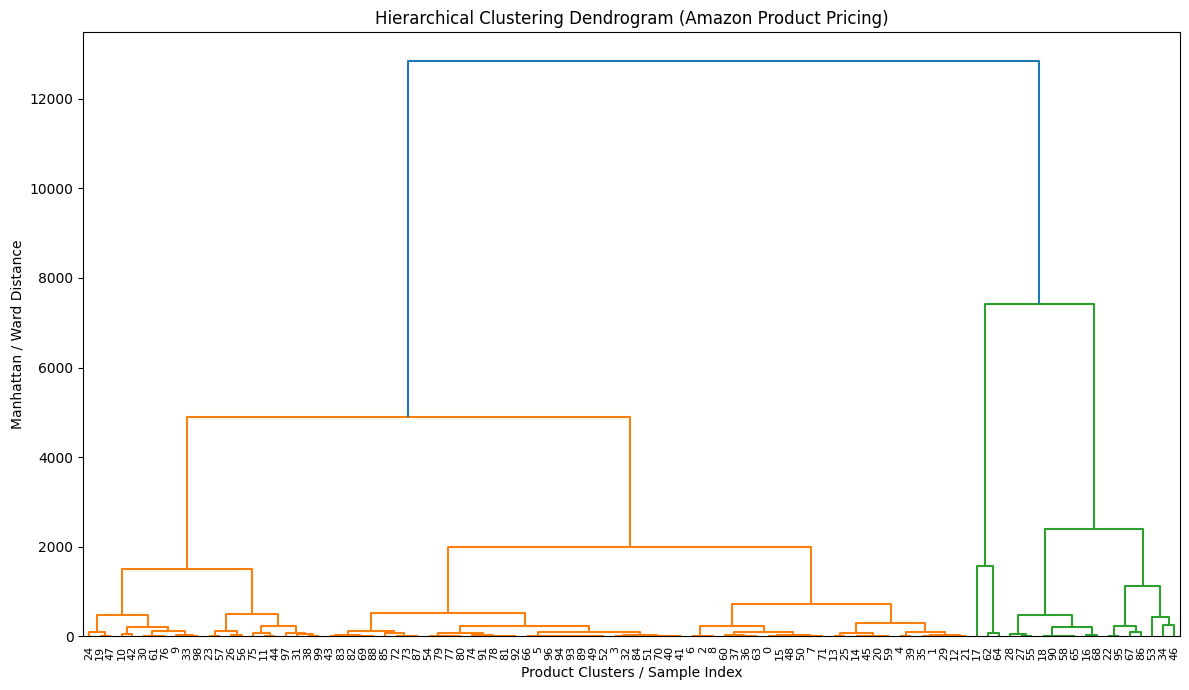

In [28]:
plt.figure(figsize=(12, 7))
plt.title('Hierarchical Clustering Dendrogram (Amazon Product Pricing)')
plt.xlabel('Product Clusters / Sample Index')
plt.ylabel('Manhattan / Ward Distance')

dendrogram(
    linkage(custom[:100], method='ward'),  # Displaying first 100 products for clear branch visibility
    leaf_rotation=90.,
    leaf_font_size=8.
)

plt.tight_layout()
plt.show()